# <center>Taller de Aprendizaje Automático</center>
## <center>4TA adaptado a Higgs: detección de anomalías sobre datos procesados</center>

Este notebook replica la lógica central del taller de detección de anomalías, pero usando los datos procesados del proyecto Higgs guardados en `data/higgs-boson/processed/i1/`.

Supuesto de trabajo para esta adaptación:
- clase normal: `b`
- clase anómala: `s`

La idea es entrenar detectores no supervisados únicamente con muestras normales y luego evaluar qué tan bien separan normales de anomalías en validación y test.


## Objetivos

- Cargar los datos procesados del intento 1 de Higgs, incluyendo `X_test_processed`.
- Preparar una partición `train/validacion` sobre el dataset etiquetado.
- Entrenar detectores de anomalías basados en PCA, K-Means y GMM usando solo normales (`b`).
- Seleccionar umbrales usando validación.
- Comparar todos los métodos con métricas consistentes en validación y usar el `test` externo para scoring e inspección.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import BaseEstimator, OutlierMixin
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.utils.validation import check_array, check_is_fitted


In [2]:
def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raiz del proyecto.")


project_root = find_project_root()
processed_dir = project_root / "data" / "higgs-boson" / "processed" / "i1"

required_files = [
    "X_train_processed.csv",
    "y_train.csv",
    "X_test_processed.csv",
    "test_event_id.csv",
]
missing_files = [name for name in required_files if not (processed_dir / name).exists()]
if missing_files:
    raise FileNotFoundError(
        "Faltan archivos procesados esperados: " + ", ".join(missing_files)
    )

X_labeled = pd.read_csv(processed_dir / "X_train_processed.csv")
y_raw = pd.read_csv(processed_dir / "y_train.csv")
X_test_processed = pd.read_csv(processed_dir / "X_test_processed.csv")
test_event_id = pd.read_csv(processed_dir / "test_event_id.csv")

if list(X_labeled.columns) != list(X_test_processed.columns):
    raise ValueError("Las columnas de train y X_test_processed no coinciden.")

if len(X_test_processed) != len(test_event_id):
    raise ValueError("La cantidad de filas de X_test_processed y test_event_id no coincide.")

y = y_raw["Label"].map({"b": 0, "s": 1})
if y.isna().any():
    raise ValueError("Se encontraron etiquetas inesperadas en y_train.csv.")

y = y.astype(int)

print(f"project_root = {project_root}")
print(f"processed_dir = {processed_dir}")
print(f"X_labeled shape = {X_labeled.shape}")
print(f"X_test_processed shape = {X_test_processed.shape}")
print(f"test_event_id shape = {test_event_id.shape}")
print("Distribucion de clases en train etiquetado (0=normal b, 1=anomalia s):")
print(y.value_counts().sort_index())

class_summary = pd.DataFrame(
    {
        "label_original": y_raw["Label"].value_counts().sort_index().index,
        "count": y_raw["Label"].value_counts().sort_index().values,
    }
)

dataset_summary = pd.DataFrame(
    {
        "dataset": ["train_etiquetado", "test_externo"],
        "rows": [len(X_labeled), len(X_test_processed)],
        "columns": [X_labeled.shape[1], X_test_processed.shape[1]],
    }
)

display(class_summary)
display(dataset_summary)

project_root = /home/santig14/fing/taa/1_TallerAA
processed_dir = /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/processed/i1
X_labeled shape = (250000, 26)
X_test_processed shape = (550000, 26)
test_event_id shape = (550000, 1)
Distribucion de clases en train etiquetado (0=normal b, 1=anomalia s):
Label
0    164333
1     85667
Name: count, dtype: int64


,label_original,count
0,b,164333
1,s,85667


,dataset,rows,columns
0,train_etiquetado,250000,26
1,test_externo,550000,26


## Preparación de conjuntos

Se arma una partición `train/validacion` estratificada a partir del dataset etiquetado. El `X_test_processed` oficial se deja aparte como conjunto externo sin etiquetas: no se usa para elegir modelos ni umbrales, solo para scoring e inspección final.

Para el entrenamiento de detectores no supervisados se toma únicamente la clase normal (`b`) del conjunto de entrenamiento. Además, se usa una submuestra controlada de normales para mantener razonable el costo de ajuste de los modelos más pesados.

In [3]:
RANDOM_STATE = 42
VALIDATION_SIZE = 0.20
NORMAL_LABEL = 0
ANOMALY_LABEL = 1
FIT_SAMPLE_SIZE = 50_000
SELECTION_SAMPLE_SIZE = 10_000

X_train_full, X_val, y_train_full, y_val = train_test_split(
    X_labeled,
    y,
    test_size=VALIDATION_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

X_train_normal = X_train_full.loc[y_train_full == NORMAL_LABEL].copy()

rng = np.random.default_rng(RANDOM_STATE)
fit_sample_size = min(FIT_SAMPLE_SIZE, len(X_train_normal))
selection_sample_size = min(SELECTION_SAMPLE_SIZE, len(X_train_normal))
fit_sample_idx = rng.choice(X_train_normal.index.to_numpy(), size=fit_sample_size, replace=False)
selection_sample_idx = rng.choice(X_train_normal.index.to_numpy(), size=selection_sample_size, replace=False)

X_train_normal_fit = X_train_normal.loc[fit_sample_idx].sort_index().copy()
X_train_normal_selection = X_train_normal.loc[selection_sample_idx].sort_index().copy()

split_summary = pd.DataFrame(
    {
        "subset": [
            "train_full",
            "validacion",
            "test_externo_processed",
            "train_normal_only",
            "train_normal_fit_sample",
            "train_normal_selection_sample",
        ],
        "rows": [
            len(X_train_full),
            len(X_val),
            len(X_test_processed),
            len(X_train_normal),
            len(X_train_normal_fit),
            len(X_train_normal_selection),
        ],
    }
)

target_summary = pd.DataFrame(
    {
        "subset": ["train_full", "validacion"],
        "normal_b": [
            int((y_train_full == NORMAL_LABEL).sum()),
            int((y_val == NORMAL_LABEL).sum()),
        ],
        "anomaly_s": [
            int((y_train_full == ANOMALY_LABEL).sum()),
            int((y_val == ANOMALY_LABEL).sum()),
        ],
    }
)

external_test_summary = pd.DataFrame(
    {
        "rows": [len(X_test_processed)],
        "columns": [X_test_processed.shape[1]],
        "event_id_min": [int(test_event_id["EventId"].min())],
        "event_id_max": [int(test_event_id["EventId"].max())],
    },
    index=["test_externo"],
)

display(split_summary)
display(target_summary)
display(external_test_summary)

,subset,rows
0,train_full,200000
1,validacion,50000
2,test_externo_processed,550000
3,train_normal_only,131466
4,train_normal_fit_sample,50000
5,train_normal_selection_sample,10000


,subset,normal_b,anomaly_s
0,train_full,131466,68534
1,validacion,32867,17133


,rows,columns,event_id_min,event_id_max
test_externo,550000,26,350000,899999


In [4]:
def choose_threshold(
    y_true: pd.Series,
    scores: np.ndarray,
    min_precision: float = 0.95,
) -> dict[str, float | np.ndarray]:
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    if len(thresholds) == 0:
        raise ValueError("No se pudo calcular un threshold en validacion.")

    precision_candidates = precision[:-1]
    recall_candidates = recall[:-1]

    high_precision_mask = precision_candidates >= min_precision
    if np.any(high_precision_mask):
        candidate_indices = np.where(high_precision_mask)[0]
        best_idx = candidate_indices[np.argmax(recall_candidates[high_precision_mask])]
    else:
        f1_candidates = 2 * precision_candidates * recall_candidates / np.clip(
            precision_candidates + recall_candidates,
            1e-12,
            None,
        )
        best_idx = int(np.argmax(f1_candidates))

    best_threshold = float(thresholds[best_idx])
    return {
        "precision_curve": precision,
        "recall_curve": recall,
        "thresholds": thresholds,
        "best_threshold": best_threshold,
        "best_idx": int(best_idx),
    }


def build_metric_row(y_true: pd.Series, y_pred: np.ndarray, method_name: str, split_name: str) -> dict[str, float | str]:
    return {
        "method": method_name,
        "split": split_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "predicted_anomaly_rate": float(np.mean(y_pred)),
    }


def build_external_summary(
    method_name: str,
    scores: np.ndarray,
    y_pred: np.ndarray,
    threshold: float,
) -> dict[str, float | str]:
    return {
        "method": method_name,
        "rows": int(len(scores)),
        "threshold": float(threshold),
        "score_mean": float(np.mean(scores)),
        "score_std": float(np.std(scores)),
        "score_p95": float(np.percentile(scores, 95)),
        "score_p99": float(np.percentile(scores, 99)),
        "predicted_anomaly_rate": float(np.mean(y_pred)),
    }


def build_top_external_anomalies(
    event_ids: pd.DataFrame,
    scores: np.ndarray,
    y_pred: np.ndarray,
    n: int = 10,
) -> pd.DataFrame:
    top_indices = np.argsort(scores)[-n:][::-1]
    return (
        pd.DataFrame(
            {
                "EventId": event_ids.iloc[top_indices]["EventId"].to_numpy(),
                "anomaly_score": scores[top_indices],
                "predicted_anomaly": y_pred[top_indices],
            }
        )
        .reset_index(drop=True)
    )


def plot_score_distributions(normal_scores: np.ndarray, anomaly_scores: np.ndarray, title: str) -> None:
    plt.figure(figsize=(9, 4))
    plt.hist(normal_scores, bins=50, alpha=0.6, label="Normal (b)")
    plt.hist(anomaly_scores, bins=50, alpha=0.6, label="Anomalia (s)")
    plt.title(title)
    plt.xlabel("Score de anomalia")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.tight_layout()
    plt.show()


def evaluate_detector(
    detector,
    X_train_normal_fit: pd.DataFrame,
    X_val: pd.DataFrame,
    y_val: pd.Series,
    X_test_processed: pd.DataFrame,
    test_event_id: pd.DataFrame,
    method_name: str,
    min_precision: float = 0.95,
) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, object]]:
    detector.fit(X_train_normal_fit)

    val_scores = detector.score(X_val)
    external_scores = detector.score(X_test_processed)

    threshold_info = choose_threshold(y_val, val_scores, min_precision=min_precision)
    threshold = threshold_info["best_threshold"]

    y_val_pred = (val_scores > threshold).astype(int)
    y_external_pred = (external_scores > threshold).astype(int)

    metrics_df = pd.DataFrame(
        [
            build_metric_row(y_val, y_val_pred, method_name, "validacion"),
        ]
    )
    metrics_df["threshold"] = threshold

    external_summary_df = pd.DataFrame(
        [
            build_external_summary(method_name, external_scores, y_external_pred, threshold),
        ]
    )

    details = {
        "detector": detector,
        "threshold": threshold,
        "threshold_info": threshold_info,
        "val_scores": val_scores,
        "external_scores": external_scores,
        "y_val_pred": y_val_pred,
        "y_external_pred": y_external_pred,
        "top_external_anomalies": build_top_external_anomalies(
            test_event_id,
            external_scores,
            y_external_pred,
        ),
    }
    return metrics_df, external_summary_df, details

## PCA

Primero se analiza cuántos componentes hacen falta para preservar la mayor parte de la varianza de los datos normales. Luego se construye un detector de anomalías basado en error de reconstrucción.


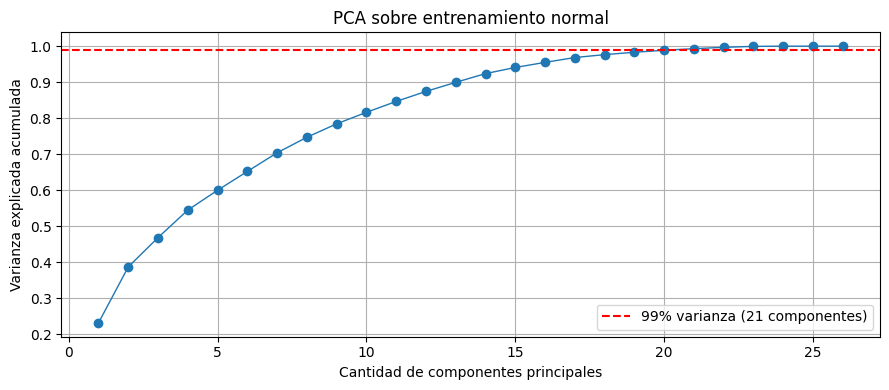

Cantidad de componentes para preservar 99% de la varianza: 21


In [5]:
pca_full = PCA().fit(X_train_normal_fit)
cum_variance = np.cumsum(pca_full.explained_variance_ratio_)
n_99 = int(np.argmax(cum_variance >= 0.99) + 1)

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(cum_variance) + 1), cum_variance, marker="o", linewidth=1)
plt.axhline(y=0.99, color="red", linestyle="--", label=f"99% varianza ({n_99} componentes)")
plt.xlabel("Cantidad de componentes principales")
plt.ylabel("Varianza explicada acumulada")
plt.title("PCA sobre entrenamiento normal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Cantidad de componentes para preservar 99% de la varianza: {n_99}")


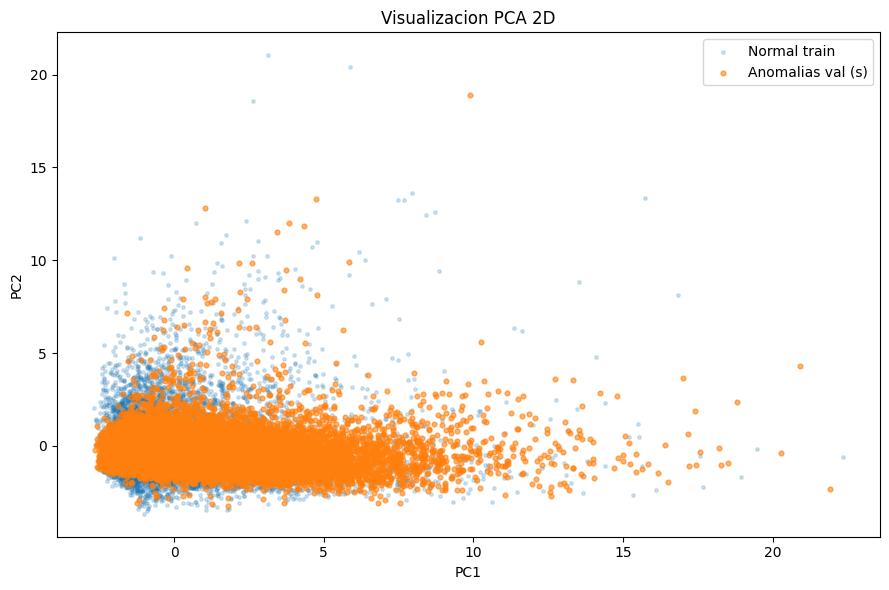

In [6]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_normal_2d = pca_2d.fit_transform(X_train_normal_selection)
X_val_2d = pca_2d.transform(X_val)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_train_normal_2d[:, 0],
    X_train_normal_2d[:, 1],
    alpha=0.2,
    s=6,
    label="Normal train",
)
plt.scatter(
    X_val_2d[y_val.to_numpy() == ANOMALY_LABEL, 0],
    X_val_2d[y_val.to_numpy() == ANOMALY_LABEL, 1],
    alpha=0.6,
    s=12,
    label="Anomalias val (s)",
)
plt.title("Visualizacion PCA 2D")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.tight_layout()
plt.show()


In [7]:
class ADPCA(BaseEstimator, OutlierMixin):
    def __init__(self, n_components: float | int | None = 0.99):
        self.n_components = n_components

    def fit(self, X: pd.DataFrame | np.ndarray, y: pd.Series | None = None):
        X_checked = check_array(X)
        self.pca_ = PCA(n_components=self.n_components, random_state=RANDOM_STATE)
        self.pca_.fit(X_checked)
        return self

    def score(self, X: pd.DataFrame | np.ndarray, y: pd.Series | None = None) -> np.ndarray:
        X_checked = check_array(X)
        check_is_fitted(self, ["pca_"])
        X_proj = self.pca_.transform(X_checked)
        X_recon = self.pca_.inverse_transform(X_proj)
        return np.sqrt(np.mean((X_checked - X_recon) ** 2, axis=1))


,method,split,accuracy,precision,recall,f1,predicted_anomaly_rate,threshold
0,PCA,validacion,0.4306,0.3659,0.9029,0.5208,0.8455,0.022


,method,rows,threshold,score_mean,score_std,score_p95,score_p99,predicted_anomaly_rate
0,PCA,550000,0.022,0.0596,0.0568,0.1509,0.2865,0.8433


Threshold elegido para PCA: 0.021997
Top 10 casos mas anomalos de X_test_processed segun PCA:


,EventId,anomaly_score,predicted_anomaly
0,691973,2.0777,1
1,604435,2.0428,1
2,454293,1.9479,1
3,517450,1.5580,1
4,464871,1.4838,1
5,768668,1.4731,1
6,670757,1.4367,1
7,705055,1.3941,1
8,423709,1.3931,1
9,530698,1.3741,1


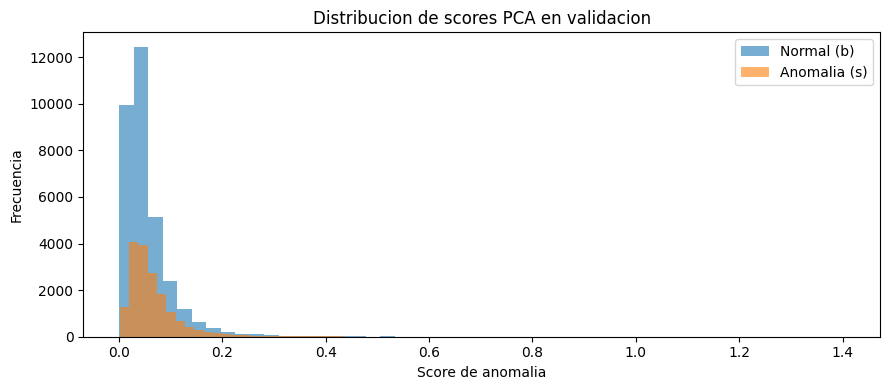

In [8]:
pca_metrics, pca_external_summary, pca_details = evaluate_detector(
    detector=ADPCA(n_components=0.99),
    X_train_normal_fit=X_train_normal_fit,
    X_val=X_val,
    y_val=y_val,
    X_test_processed=X_test_processed,
    test_event_id=test_event_id,
    method_name="PCA",
)

display(pca_metrics.round(4))
display(pca_external_summary.round(4))
print(f"Threshold elegido para PCA: {pca_details['threshold']:.6f}")
print("Top 10 casos mas anomalos de X_test_processed segun PCA:")
display(pca_details["top_external_anomalies"].round(4))

plot_score_distributions(
    normal_scores=pca_details["val_scores"][y_val.to_numpy() == NORMAL_LABEL],
    anomaly_scores=pca_details["val_scores"][y_val.to_numpy() == ANOMALY_LABEL],
    title="Distribucion de scores PCA en validacion",
)

## K-Means

Se elige un número de clusters usando `silhouette_score` sobre una submuestra de entrenamiento normal y luego se usa la distancia al centroide más cercano como score de anomalía.


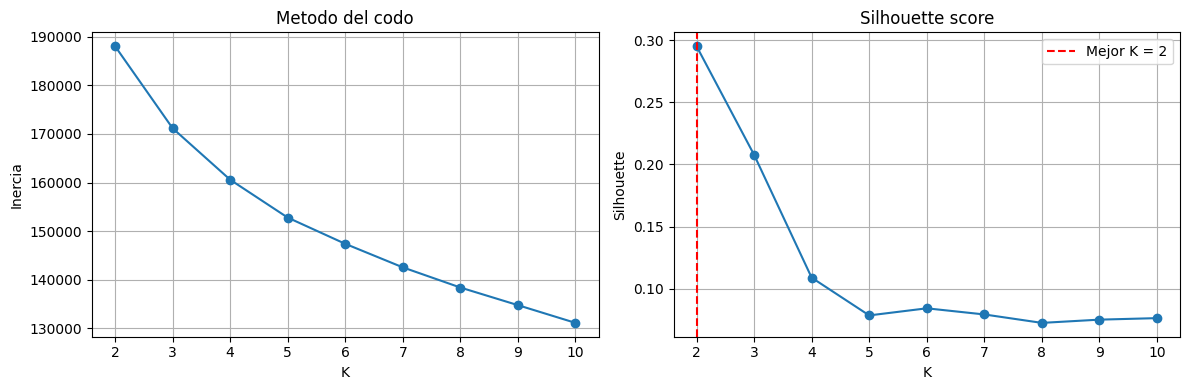

K sugerido para K-Means: 2


In [9]:
k_values = list(range(2, 11))
inertias = []
sil_scores = []

X_kmeans_selection = X_train_normal_selection.to_numpy()

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = kmeans.fit_predict(X_kmeans_selection)
    inertias.append(kmeans.inertia_)

    # silhouette_score puede ser costoso; con 10k muestras y 26 features sigue siendo razonable.
    from sklearn.metrics import silhouette_score
    sil_scores.append(silhouette_score(X_kmeans_selection, labels))

best_k = int(k_values[int(np.argmax(sil_scores))])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_values, inertias, marker="o")
ax[0].set_title("Metodo del codo")
ax[0].set_xlabel("K")
ax[0].set_ylabel("Inercia")
ax[0].grid(True)

ax[1].plot(k_values, sil_scores, marker="o")
ax[1].axvline(best_k, color="red", linestyle="--", label=f"Mejor K = {best_k}")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("K")
ax[1].set_ylabel("Silhouette")
ax[1].grid(True)
ax[1].legend()

plt.tight_layout()
plt.show()
print(f"K sugerido para K-Means: {best_k}")


In [10]:
class ADKMeans(BaseEstimator, OutlierMixin):
    def __init__(self, n_clusters: int = 4, random_state: int = RANDOM_STATE, n_init: int = 10):
        self.n_clusters = n_clusters
        self.random_state = random_state
        self.n_init = n_init

    def fit(self, X: pd.DataFrame | np.ndarray, y: pd.Series | None = None):
        X_checked = check_array(X)
        self.kmeans_ = KMeans(
            n_clusters=self.n_clusters,
            random_state=self.random_state,
            n_init=self.n_init,
        )
        self.kmeans_.fit(X_checked)
        return self

    def score(self, X: pd.DataFrame | np.ndarray, y: pd.Series | None = None) -> np.ndarray:
        X_checked = check_array(X)
        check_is_fitted(self, ["kmeans_"])
        distances = self.kmeans_.transform(X_checked)
        return np.min(distances, axis=1)


,method,split,accuracy,precision,recall,f1,predicted_anomaly_rate,threshold
0,KMeans,validacion,0.4148,0.3605,0.9141,0.517,0.869,2.9653


,method,rows,threshold,score_mean,score_std,score_p95,score_p99,predicted_anomaly_rate
0,KMeans,550000,2.9653,4.0964,1.4832,6.3066,10.2015,0.8679


Threshold elegido para K-Means: 2.965328
Top 10 casos mas anomalos de X_test_processed segun K-Means:


,EventId,anomaly_score,predicted_anomaly
0,381419,57.0898,1
1,401395,49.7150,1
2,434628,45.3214,1
3,848978,41.1685,1
4,510225,40.8336,1
5,673255,40.0838,1
6,849985,38.4245,1
7,403056,37.6335,1
8,726639,37.1420,1
9,551267,35.4020,1


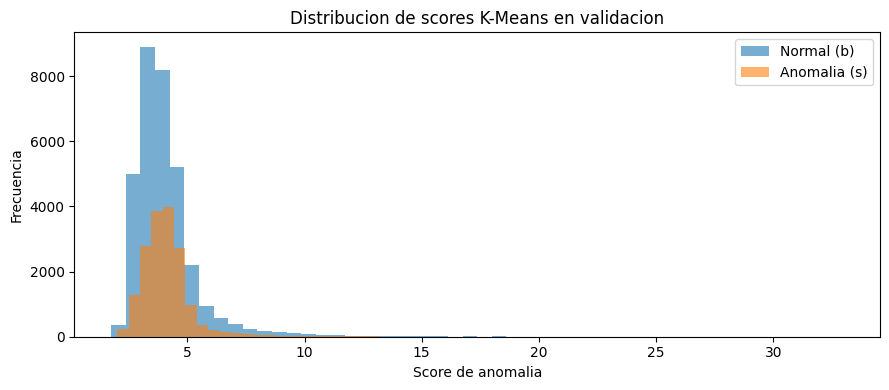

In [11]:
kmeans_metrics, kmeans_external_summary, kmeans_details = evaluate_detector(
    detector=ADKMeans(n_clusters=best_k),
    X_train_normal_fit=X_train_normal_fit,
    X_val=X_val,
    y_val=y_val,
    X_test_processed=X_test_processed,
    test_event_id=test_event_id,
    method_name="KMeans",
)

display(kmeans_metrics.round(4))
display(kmeans_external_summary.round(4))
print(f"Threshold elegido para K-Means: {kmeans_details['threshold']:.6f}")
print("Top 10 casos mas anomalos de X_test_processed segun K-Means:")
display(kmeans_details["top_external_anomalies"].round(4))

plot_score_distributions(
    normal_scores=kmeans_details["val_scores"][y_val.to_numpy() == NORMAL_LABEL],
    anomaly_scores=kmeans_details["val_scores"][y_val.to_numpy() == ANOMALY_LABEL],
    title="Distribucion de scores K-Means en validacion",
)

## GMM

Se exploran distintas configuraciones de mezclas gaussianas usando BIC sobre una submuestra normal. Luego se usa la log-verosimilitud negativa como score de anomalía.


In [12]:
gmm_results = []
X_gmm_selection = X_train_normal_selection.to_numpy()

for covariance_type in ["full", "diag", "spherical"]:
    for n_components in range(1, 9):
        gmm = GaussianMixture(
            n_components=n_components,
            covariance_type=covariance_type,
            n_init=3,
            random_state=RANDOM_STATE,
        )
        gmm.fit(X_gmm_selection)
        gmm_results.append(
            {
                "covariance_type": covariance_type,
                "n_components": n_components,
                "bic": gmm.bic(X_gmm_selection),
                "aic": gmm.aic(X_gmm_selection),
            }
        )

gmm_results_df = pd.DataFrame(gmm_results).sort_values("bic").reset_index(drop=True)
best_gmm_row = gmm_results_df.iloc[0]
best_gmm_components = int(best_gmm_row["n_components"])
best_gmm_covariance = str(best_gmm_row["covariance_type"])

print("Mejor configuracion GMM segun BIC:")
print(best_gmm_row.to_string())
display(gmm_results_df.head(10))


Mejor configuracion GMM segun BIC:
covariance_type             full
n_components                   7
bic               -491615.678393
aic               -510687.028677


,covariance_type,n_components,bic,aic
0,full,7,-491615.678393,-510687.028677
1,full,8,-490005.179704,-511802.038649
2,full,6,-455245.710679,-471591.552303
3,full,5,-450399.959879,-464020.292842
4,full,4,-449117.534950,-460012.359252
5,diag,8,-224759.210033,-227809.184011
6,diag,7,-211412.952432,-214080.778369
7,diag,6,-193563.464235,-195849.142133
8,diag,5,-175114.961009,-177018.490868
9,full,3,-94570.327761,-102739.643402


In [13]:
class ADGMM(BaseEstimator, OutlierMixin):
    def __init__(
        self,
        n_components: int = 2,
        covariance_type: str = "full",
        random_state: int = RANDOM_STATE,
        n_init: int = 3,
    ):
        self.n_components = n_components
        self.covariance_type = covariance_type
        self.random_state = random_state
        self.n_init = n_init

    def fit(self, X: pd.DataFrame | np.ndarray, y: pd.Series | None = None):
        X_checked = check_array(X)
        self.gmm_ = GaussianMixture(
            n_components=self.n_components,
            covariance_type=self.covariance_type,
            random_state=self.random_state,
            n_init=self.n_init,
        )
        self.gmm_.fit(X_checked)
        return self

    def score(self, X: pd.DataFrame | np.ndarray, y: pd.Series | None = None) -> np.ndarray:
        X_checked = check_array(X)
        check_is_fitted(self, ["gmm_"])
        return -self.gmm_.score_samples(X_checked)


,method,split,accuracy,precision,recall,f1,predicted_anomaly_rate,threshold
0,GMM,validacion,0.494,0.3906,0.8514,0.5355,0.7468,-44.9437


,method,rows,threshold,score_mean,score_std,score_p95,score_p99,predicted_anomaly_rate
0,GMM,550000,-44.9437,-23.0197,19.5349,3.6072,20.4973,0.7459


Threshold elegido para GMM: -44.943710
Top 10 casos mas anomalos de X_test_processed segun GMM:


,EventId,anomaly_score,predicted_anomaly
0,510225,319.8857,1
1,381419,196.0484,1
2,403056,178.0722,1
3,438047,153.0729,1
4,429711,152.7665,1
5,453064,145.5966,1
6,784464,144.0224,1
7,401395,143.5204,1
8,554834,135.4641,1
9,762385,129.0983,1


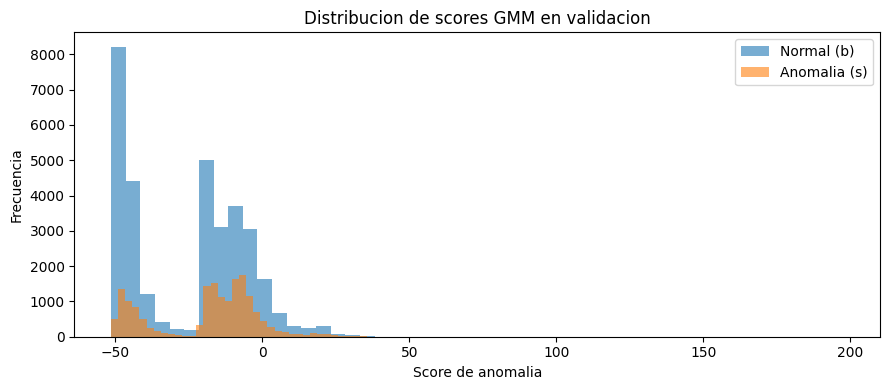

In [14]:
gmm_metrics, gmm_external_summary, gmm_details = evaluate_detector(
    detector=ADGMM(
        n_components=best_gmm_components,
        covariance_type=best_gmm_covariance,
    ),
    X_train_normal_fit=X_train_normal_fit,
    X_val=X_val,
    y_val=y_val,
    X_test_processed=X_test_processed,
    test_event_id=test_event_id,
    method_name="GMM",
)

display(gmm_metrics.round(4))
display(gmm_external_summary.round(4))
print(f"Threshold elegido para GMM: {gmm_details['threshold']:.6f}")
print("Top 10 casos mas anomalos de X_test_processed segun GMM:")
display(gmm_details["top_external_anomalies"].round(4))

plot_score_distributions(
    normal_scores=gmm_details["val_scores"][y_val.to_numpy() == NORMAL_LABEL],
    anomaly_scores=gmm_details["val_scores"][y_val.to_numpy() == ANOMALY_LABEL],
    title="Distribucion de scores GMM en validacion",
)

## Comparativa final

La comparación homogénea entre métodos se hace en validación, porque es el único split con etiquetas disponibles fuera del entrenamiento. En paralelo, se resume cómo se comporta cada detector sobre `X_test_processed` usando el umbral elegido en validación.

,method,split,accuracy,precision,recall,f1,predicted_anomaly_rate,threshold
0,GMM,validacion,0.4940,0.3906,0.8514,0.5355,0.7468,-44.9437
1,PCA,validacion,0.4306,0.3659,0.9029,0.5208,0.8455,0.0220
2,KMeans,validacion,0.4148,0.3605,0.9141,0.5170,0.8690,2.9653


,method,rows,threshold,score_mean,score_std,score_p95,score_p99,predicted_anomaly_rate
0,KMeans,550000,2.9653,4.0964,1.4832,6.3066,10.2015,0.8679
1,PCA,550000,0.0220,0.0596,0.0568,0.1509,0.2865,0.8433
2,GMM,550000,-44.9437,-23.0197,19.5349,3.6072,20.4973,0.7459


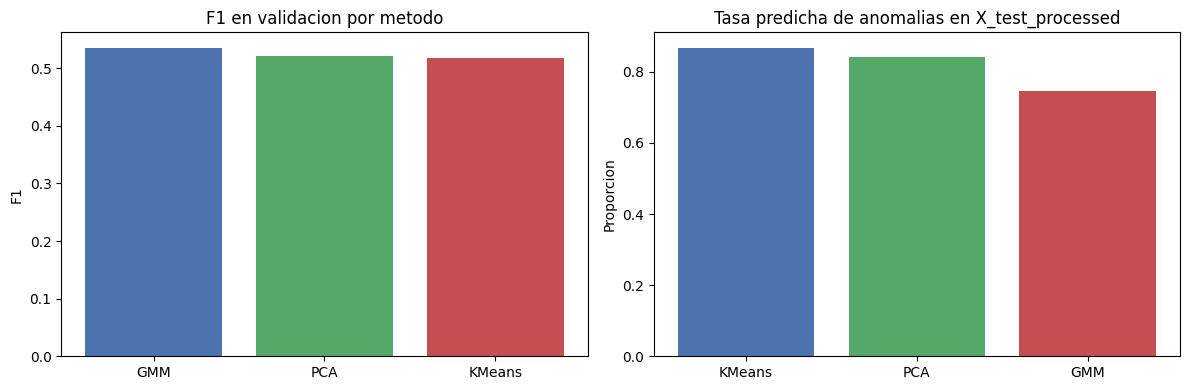

In [15]:
comparison_df = pd.concat([pca_metrics, kmeans_metrics, gmm_metrics], ignore_index=True)
comparison_df = comparison_df.sort_values(["f1", "precision"], ascending=[False, False]).reset_index(drop=True)

external_comparison_df = pd.concat(
    [pca_external_summary, kmeans_external_summary, gmm_external_summary],
    ignore_index=True,
)
external_comparison_df = external_comparison_df.sort_values(
    ["predicted_anomaly_rate", "score_p99"],
    ascending=[False, False],
).reset_index(drop=True)

display(comparison_df.round(4))
display(external_comparison_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(comparison_df["method"], comparison_df["f1"], color=["#4C72B0", "#55A868", "#C44E52"])
axes[0].set_title("F1 en validacion por metodo")
axes[0].set_ylabel("F1")

axes[1].bar(
    external_comparison_df["method"],
    external_comparison_df["predicted_anomaly_rate"],
    color=["#4C72B0", "#55A868", "#C44E52"],
)
axes[1].set_title("Tasa predicha de anomalias en X_test_processed")
axes[1].set_ylabel("Proporcion")

plt.tight_layout()
plt.show()

## Conclusión

- Con los outputs actuales, `GMM` es el mejor candidato a baseline no supervisado para este dataset procesado. En validación obtuvo el mejor `F1` (`0.5355`) y también la mejor precisión (`0.3906`) de los tres métodos, manteniendo un recall alto (`0.8514`).
- `PCA` y `K-Means` empujan un poco más el recall (`0.9029` y `0.9141`), pero lo hacen a costa de marcar demasiados ejemplos como anómalos. En validación predicen anomalía en `84.55%` y `86.90%` de los casos, mientras que `GMM` baja eso a `74.68%`.
- Ese mismo patrón se repite en `X_test_processed`: `K-Means` queda como el método más agresivo (`86.79%` de anomalías predichas), `PCA` también mantiene una tasa muy alta (`84.33%`) y `GMM` vuelve a ser el más conservador (`74.59%`).
- En conjunto, los tres detectores parecen sobre-detectar anomalías respecto al problema etiquetado, así que el siguiente paso razonable no es cambiar de método sino recalibrar el umbral o revisar el criterio con el que se elige. Si hubiera que seguir con uno solo en este notebook, `GMM` es la opción más defendible para continuar el baseline.